In [2]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path("/data/ghs/projects/tianyi-micrograd")

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Python:", sys.executable)
print("工作目录:", Path.cwd())

Python: /data/ghs/miniconda3/envs/agent/bin/python
工作目录: /data/ghs/projects/tianyi-micrograd


In [3]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from examples.moons_utils import make_data, make_model, loss_and_accuracy

100


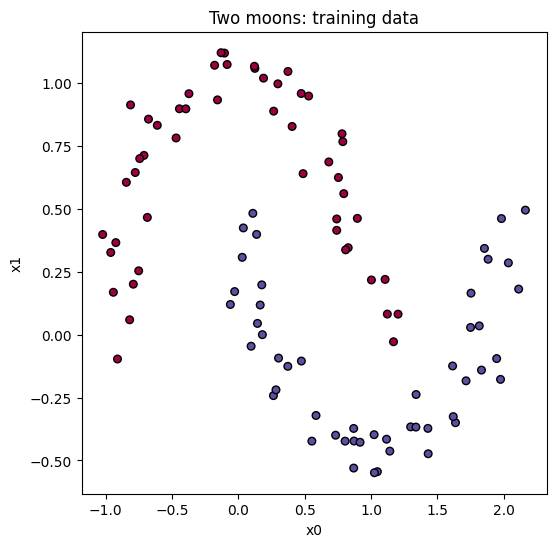

In [ ]:
xs, ys = make_data()

points = np.asarray(xs)
print(len(points))

colors = np.array([int(y > 0) for y in ys])


fig , ax = plt.subplots(figsize=(6,6))
ax.scatter(points[:, 0], points[:, 1], c=colors, cmap="Spectral",
           vmin=0, vmax=1, edgecolors="k", s=30)
ax.set(xlabel="x0", ylabel="x1", title="Two moons: training data")
plt.show()


In [8]:
model = make_model()
initial_loss, initial_accuracy = loss_and_accuracy(model, xs, ys)
print(model)
print("参数数目:", len(model.parameters()))
print(f"初始总损失: {initial_loss.data:.6f}, 训练准确率: {initial_accuracy:.1%}")

MLP of [Layer of [ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2), ReLUNeuron (2)], Layer of [ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16), ReLUNeuron (16)], Layer of [LinearNeuron (16)]]
参数数目: 337
初始总损失: 0.895844, 训练准确率: 50.0%


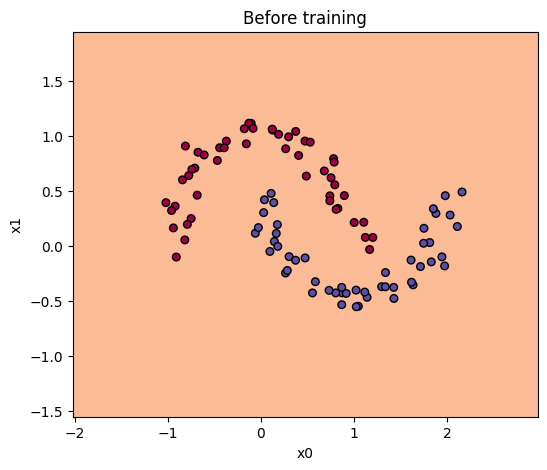

In [9]:
def plot_boundary(model, xs, ys, title):
    points = np.asarray(xs)
    h = 0.25
    x_min, x_max = points[:, 0].min() - 1, points[:, 0].max() + 1
    y_min, y_max = points[:, 1].min() - 1, points[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    predicted = np.array([model(row.tolist()).data > 0 for row in grid])
    predicted = predicted.reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.contourf(xx, yy, predicted, levels=[-0.5, 0.5, 1.5],
                cmap="Spectral", alpha=0.6)
    ax.scatter(points[:, 0], points[:, 1], c=[int(y > 0) for y in ys],
               cmap="Spectral", vmin=0, vmax=1, edgecolors="k", s=30)
    ax.set(xlabel="x0", ylabel="x1", title=title)
    return fig


initial_boundary_fig = plot_boundary(model, xs, ys, "Before training")
plt.show()

In [10]:
model = make_model()
steps = 100
history = []

for step in range(steps):
    total_loss, accuracy = loss_and_accuracy(model, xs, ys)
    history.append((step, total_loss.data, accuracy))

    model.zero_grad()
    total_loss.backward()
    learning_rate = 1.0 - 0.9 * step / steps
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    if step % 10 == 0 or step == steps - 1:
        print(f"更新前 {step:03d}: loss={total_loss.data:.6f}, "
              f"train_acc={accuracy:.1%}, lr={learning_rate:.3f}")

final_loss, final_accuracy = loss_and_accuracy(model, xs, ys)
history.append((steps, final_loss.data, final_accuracy))
print(f"完成 {steps} 次更新: loss={final_loss.data:.6f}, "
      f"train_acc={final_accuracy:.1%}")

更新前 000: loss=0.895844, train_acc=50.0%, lr=1.000
更新前 010: loss=0.245070, train_acc=91.0%, lr=0.910
更新前 020: loss=0.189775, train_acc=91.0%, lr=0.820
更新前 030: loss=0.117313, train_acc=95.0%, lr=0.730
更新前 040: loss=0.060160, train_acc=100.0%, lr=0.640
更新前 050: loss=0.098751, train_acc=96.0%, lr=0.550
更新前 060: loss=0.032597, train_acc=99.0%, lr=0.460
更新前 070: loss=0.014230, train_acc=100.0%, lr=0.370
更新前 080: loss=0.012319, train_acc=100.0%, lr=0.280
更新前 090: loss=0.010984, train_acc=100.0%, lr=0.190
更新前 099: loss=0.010978, train_acc=100.0%, lr=0.109
完成 100 次更新: loss=0.010978, train_acc=100.0%


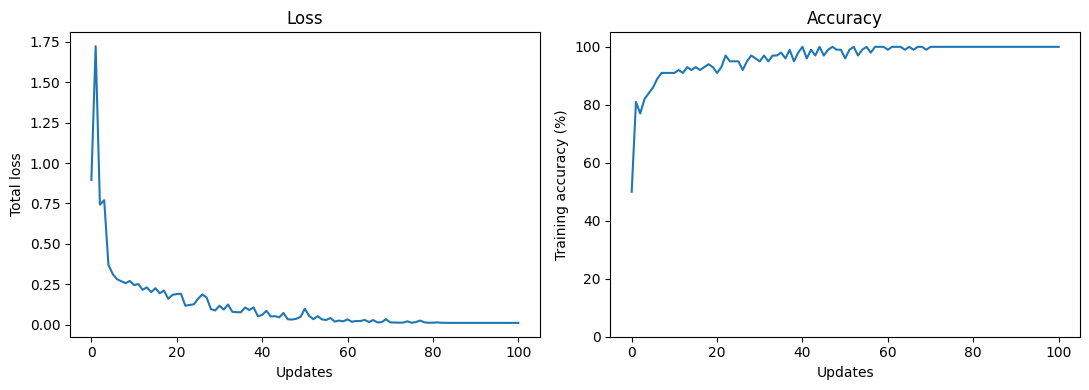

In [11]:
updates, losses, accuracies = zip(*history)

curves_fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(updates, losses)
axes[0].set(xlabel="Updates", ylabel="Total loss", title="Loss")
axes[1].plot(updates, [100 * acc for acc in accuracies])
axes[1].set(xlabel="Updates", ylabel="Training accuracy (%)",
            title="Accuracy", ylim=(0, 105))
curves_fig.tight_layout()
plt.show()

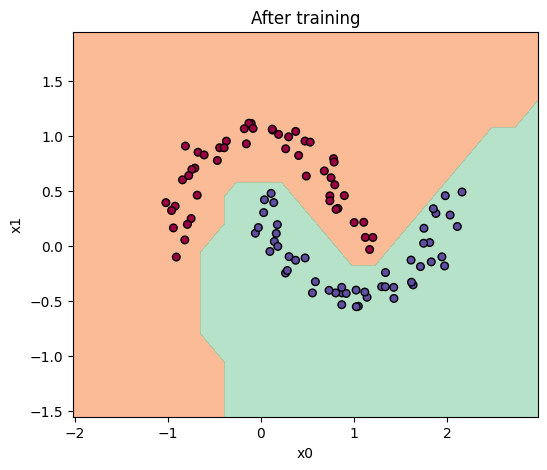

初始: loss=0.895844, train_acc=50.0%
最终: loss=0.010978, train_acc=100.0%


In [12]:
boundary_fig = plot_boundary(model, xs, ys, "After training")
plt.show()

print(f"初始: loss={history[0][1]:.6f}, train_acc={history[0][2]:.1%}")
print(f"最终: loss={history[-1][1]:.6f}, train_acc={history[-1][2]:.1%}")

In [13]:
output_dir = PROJECT_ROOT / "outputs"
output_dir.mkdir(exist_ok=True)
curves_fig.savefig(output_dir / "moons_training_curves.png", dpi=150, bbox_inches="tight")
boundary_fig.savefig(output_dir / "moons_boundary.png", dpi=150, bbox_inches="tight")